# 타이타닉 — 살았을까?

**분류** = 예/아니오를 고르는 일입니다. 여기서는 **생존(Survived)** 을 맞춥니다.  
흐름: 데이터 보기 → 비운 칸 채우기 → 숫자로 바꾸기 → 모델 학습 → 점수 확인.


In [1]:
# 표·숫자·그림 라이브러리 불러오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# read_csv = csv 파일을 표(DataFrame)로 읽기
ti_data=pd.read_csv("../data/train.csv")

In [3]:
# 표 전체를 한번 훑어보기
ti_data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 데이터 살펴보기 (EDA)

**EDA** = 모델 전에 표와 그림으로 데이터를 보는 일입니다.  
누가 더 많이 살았는지(성별·좌석 등급 등) 감을 잡습니다.


(array([ 54.,  46., 177., 169., 118.,  70.,  45.,  24.,   9.,   2.]),
 array([ 0.42 ,  8.378, 16.336, 24.294, 32.252, 40.21 , 48.168, 56.126,
        64.084, 72.042, 80.   ]),
 <BarContainer object of 10 artists>)

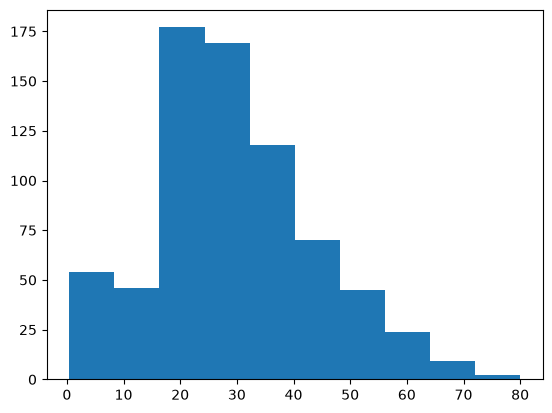

In [4]:
# age(나이)만 골라 막대 분포(히스토그램)로 보기
plt.hist(ti_data['Age'])

In [5]:
# fare = 운임. 가장 비싼 값
ti_data['Fare'].max()

np.float64(512.3292)

In [6]:
# 성별마다 몇 명인지 세기
# value_counts = 값별 개수. 기본은 빈칸(결측) 빼고 셈
ti_data['Sex'].value_counts(dropna=False)

Sex
male      577
female    314
Name: count, dtype: int64

In [7]:
# 생존/사망 각각 몇 명인지 세기
ti_data['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [8]:
# Survived = 생존 여부(정답). 입력에서는 뺌
# 정답 열은 모델이 맞힐 대상이라 문제에 넣으면 안 됨
# Survived를 지우고 남은 열만 입력(문제)으로 씀
features=ti_data.drop('Survived', axis=1)

In [9]:
# 표 전체를 한번 훑어보기
features

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [10]:
# inplace=True = 원본을 바로 고침. 새 변수에 대입할 필요 없음
features=features.drop(['PassengerId','Name','Ticket'], axis=1)

In [11]:
# 표 전체를 한번 훑어보기
features

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,3,male,22.0,1,0,7.2500,NaN,S
1,1,female,38.0,1,0,71.2833,C85,C
2,3,female,26.0,0,0,7.9250,NaN,S
3,1,female,35.0,1,0,53.1000,C123,S
4,3,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...
886,2,male,27.0,0,0,13.0000,NaN,S
887,1,female,19.0,0,0,30.0000,B42,S
888,3,female,NaN,1,2,23.4500,NaN,S
889,1,male,26.0,0,0,30.0000,C148,C


In [12]:
# Cabin(객실) 열을 지움. inplace=True = 원본을 바로 고침
features.drop(['Cabin'], axis=1, inplace=True)

C:\Users\dmsrh\AppData\Local\Temp\ipykernel_45328\259190439.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  features.drop(['Cabin'], axis=1, inplace=True)


In [13]:
# 표 전체를 한번 훑어보기
features

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...
886,2,male,27.0,0,0,13.0000,S
887,1,female,19.0,0,0,30.0000,S
888,3,female,NaN,1,2,23.4500,S
889,1,male,26.0,0,0,30.0000,C


## 결측 채우기

**결측** = 비어 있는 칸입니다.  
비어 있으면 모델이 계산을 못 하니, 중앙값·최빈값 등으로 채우거나 칸을 정리합니다.


In [14]:
# 결측 = 빈칸(NaN). 어디가 비었는지 확인
# isna() = 빈칸이면 True, 아니면 False
features['Age'].isna().sum()

np.int64(177)

In [15]:
# Fare(운임) 빈칸이 몇 개인지 세기
features['Fare'].isna().sum()

np.int64(0)

In [16]:
# 라벨 = 정답
label=ti_data['Survived']
label

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [17]:
# 정답 쪽에 빈칸이 있는지 확인
label.isna().sum()

np.int64(0)

In [18]:
# 문제 = 입력 = 피처(feature)
# 정답 = 출력 = 라벨(label)

# 입력(피처) 쪽에 빈칸이 있는지 확인
features.isna().sum()

Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [19]:
# 빈칸을 값으로 채워 보기
# 탑승자 나이의 평균 구하기
features['Age'].mean()

np.float64(29.69911764705882)

In [20]:
# 나이 빈칸에 평균 나이를 넣기
features['Age']=features['Age'].fillna(features['Age'].mean())

In [21]:
# 나이를 채운 뒤 빈칸이 남았는지 확인
features.isna().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64

In [22]:
# Embarked = 탑승 항구. 값별 개수로 가장 많은 항구 찾기
features['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [23]:
# Embarked(탑승 항구) 빈칸에 S 넣기
features['Embarked']=features['Embarked'].fillna('S')

In [24]:
# 항구까지 채운 뒤 빈칸이 없는지 확인
features.isna().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

> **쉬운 말**
> 표에 빈칸이 있으면 모델이 계산을 못 합니다.
> 나이는 평균으로, 탑승 항구는 가장 많이 나온 값으로 채워 모든 줄을 채웠습니다.


In [25]:
# scikit-learn = 머신러닝 도구 모음. 없으면 설치
pip install scikit-learn

SyntaxError: invalid syntax (2016372649.py, line 2)

## 문자 → 숫자, 크기 맞추기

모델은 글자보다 **숫자**를 좋아합니다. 성별 등을 0/1로 바꿉니다.  
**스케일링** = 숫자 크기를 맞춰 주는 일. 연습 데이터에만 fit 합니다.


In [ ]:
# LabelEncoder = 글자 값을 숫자로 바꿔 주는 도구
from sklearn.preprocessing import LabelEncoder

In [ ]:
# 많은 모델은 숫자만 받음. 글자 라벨을 숫자로 바꿔야 함
# 범주형 = 몇 가지 종류로 나뉜 값. 그걸 숫자로 인코딩
label_encoder=LabelEncoder()

In [ ]:
# fit_transform으로 한 번에 숫자화(예: male→1, female→0)
# fit_transform = fit(규칙 학습) + transform(변환)
features['Sex']=label_encoder.fit_transform(features['Sex'])

In [ ]:
# 표 전체를 한번 훑어보기
features

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.000000,1,0,7.2500,S
1,1,0,38.000000,1,0,71.2833,C
2,3,0,26.000000,0,0,7.9250,S
3,1,0,35.000000,1,0,53.1000,S
4,3,1,35.000000,0,0,8.0500,S
...,...,...,...,...,...,...,...
886,2,1,27.000000,0,0,13.0000,S
887,1,0,19.000000,0,0,30.0000,S
888,3,0,29.699118,1,2,23.4500,S
889,1,1,26.000000,0,0,30.0000,C


In [ ]:
# Embarked(탑승 항구)도 같은 방식으로 숫자화
features['Embarked']=label_encoder.fit_transform(features['Embarked'])

In [ ]:
# 표 전체를 한번 훑어보기
features

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.000000,1,0,7.2500,2
1,1,0,38.000000,1,0,71.2833,0
2,3,0,26.000000,0,0,7.9250,2
3,1,0,35.000000,1,0,53.1000,2
4,3,1,35.000000,0,0,8.0500,2
...,...,...,...,...,...,...,...
886,2,1,27.000000,0,0,13.0000,2
887,1,0,19.000000,0,0,30.0000,2
888,3,0,29.699118,1,2,23.4500,2
889,1,1,26.000000,0,0,30.0000,0


In [ ]:
# 정규화 = 값 크기를 비슷한 범위로 맞추기
# 쓸 데이터(피처) 개수를 너무 늘리지 않기
# 피처가 많으면 계산이 늘고, 정답과의 관계가 흐려짐

In [ ]:
# 표준화에 쓰는 도구 클래스
from sklearn.preprocessing import StandardScaler

In [ ]:
# StandardScaler 객체 만들기
scaler=StandardScaler()

In [ ]:
# 값 범위가 들쭉날쭉하면 학습이 흔들림
# fit = 각 열의 평균·표준편차 구하기
# transform = (값-평균)/표준편차로 바꾸기
f_scaled=scaler.fit_transform(features)

In [ ]:
# 예: 44, 16, 8...
# 평균이 대략 30일 때
# (44-30)/14 = 1
# (16-30)/14 = -1
# (값-평균)/표준편차 = 표준화


# 정규화 예: (44-0)/(80-0) = 0.55
# (값-최솟값)/(최댓값-최솟값) = 0~1 (MinMaxScaler). 범위가 0~1이어야 할 때 자주 씀

In [ ]:
# 결과를 numpy 배열로 받기
f_scaled

array([[ 0.82737724,  0.73769513, -0.5924806 , ..., -0.47367361,
        -0.50244517,  0.58595414],
       [-1.56610693, -1.35557354,  0.63878901, ..., -0.47367361,
         0.78684529, -1.9423032 ],
       [ 0.82737724, -1.35557354, -0.2846632 , ..., -0.47367361,
        -0.48885426,  0.58595414],
       ...,
       [ 0.82737724, -1.35557354,  0.        , ...,  2.00893337,
        -0.17626324,  0.58595414],
       [-1.56610693,  0.73769513, -0.2846632 , ..., -0.47367361,
        -0.04438104, -1.9423032 ],
       [ 0.82737724,  0.73769513,  0.17706291, ..., -0.47367361,
        -0.49237783, -0.67817453]], shape=(891, 7))

In [ ]:
# 다시 pandas 표(DataFrame)로 바꾸기
f_scaled=pd.DataFrame(f_scaled, columns=features.columns)
f_scaled

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0.827377,0.737695,-0.592481,0.432793,-0.473674,-0.502445,0.585954
1,-1.566107,-1.355574,0.638789,0.432793,-0.473674,0.786845,-1.942303
2,0.827377,-1.355574,-0.284663,-0.474545,-0.473674,-0.488854,0.585954
3,-1.566107,-1.355574,0.407926,0.432793,-0.473674,0.420730,0.585954
4,0.827377,0.737695,0.407926,-0.474545,-0.473674,-0.486337,0.585954
...,...,...,...,...,...,...,...
886,-0.369365,0.737695,-0.207709,-0.474545,-0.473674,-0.386671,0.585954
887,-1.566107,-1.355574,-0.823344,-0.474545,-0.473674,-0.044381,0.585954
888,0.827377,-1.355574,0.000000,0.432793,2.008933,-0.176263,0.585954
889,-1.566107,0.737695,-0.284663,-0.474545,-0.473674,-0.044381,-1.942303


(array([ 54.,  46., 177., 346., 118.,  70.,  45.,  24.,   9.,   2.]),
 array([-2.25315549, -1.64075277, -1.02835004, -0.41594732,  0.1964554 ,
         0.80885813,  1.42126085,  2.03366357,  2.6460663 ,  3.25846902,
         3.87087174]),
 <BarContainer object of 10 artists>)

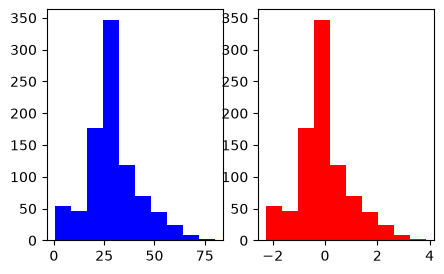

In [ ]:
# 그림 칸을 1행 2열로 나누기
fig, axis=plt.subplots(1,2, figsize=(5,3))

axis[0].hist(features['Age'], bins=10, color='blue')
axis[1].hist(f_scaled['Age'], bins=10, color='red')

In [ ]:
# iloc = 숫자 위치로 행·열 고르기
print(f_scaled.iloc[0]) #0번째 행 전체

Pclass      0.827377
Sex         0.737695
Age        -0.592481
SibSp       0.432793
Parch      -0.473674
Fare       -0.502445
Embarked    0.585954
Name: 0, dtype: float64


In [ ]:
# 0행 2열 한 칸만 보기(Age)
print(f_scaled.iloc[0,2]) #0번째 행, 2번째 열 - Age값 하나

-0.5924805998028931


In [ ]:
# 모든 행의 2열(Age)만 보기
print(f_scaled.iloc[:, 2])  #모든 행의 2번째 열

0     -0.592481
1      0.638789
2     -0.284663
3      0.407926
4      0.407926
         ...   
886   -0.207709
887   -0.823344
888    0.000000
889   -0.284663
890    0.177063
Name: Age, Length: 891, dtype: float64


> **쉬운 말**
> 모델은 글자 대신 숫자를 받으므로 성별 등을 0과 1로 바꿉니다.
> 나이와 운임처럼 크기가 다른 숫자는 스케일링으로 맞추고, 그 기준은 연습 데이터에서만 배웁니다.


## 연습/시험 & 첫 모델

**train**으로 배우고 **test**로만 점수를 봅니다.  
결정 트리·랜덤 포레스트는 “질문으로 갈라 생존을 맞추는” 나무 모델입니다.


In [ ]:
# 데이터를 섞은 뒤 학습용·검증용으로 나누기
# 흐름: 학습 → 검증 → 테스트
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(f_scaled, label, test_size=0.2, random_state=1)
# X_train = 학습용 문제(입력)
# X_test = 테스트용 문제(입력). 평가할 때 씀
# y_train = 학습용 정답
# y_test = 테스트용 정답. 성능 재는 기준

# 학습 데이터로 훈련하고, 테스트 데이터로 점수 확인
# 표준화한 데이터를 학습:테스트 = 8:2로 나누기

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# 모델 객체 만들기
dt=DecisionTreeClassifier()

In [ ]:
# 학습 데이터로 모델 훈련하기
dt.fit(X_train, y_train);

> **쉬운 말**
> 승객 표를 연습용과 시험용으로 나눈 뒤, 연습 쪽으로만 나무 모델을 가르칩니다.
> fit은 입력과 정답을 보고 생존 패턴을 기억하는 단계입니다.


In [ ]:
# 학습 문제에 대한 예측값 만들기
dt_train=dt.predict(X_train)
dt_train

array([1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1,

In [ ]:
# 테스트 문제에 대한 예측값 만들기
dt_test=dt.predict(X_test)
dt_test

array([1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 1])

In [ ]:
# 학습 데이터 정확도 계산
acc_train=accuracy_score(y_train, dt_train)
acc_train

0.9873595505617978

In [ ]:
# 테스트 데이터 정확도 계산
# 테스트 정답과 예측을 비교해 맞힌 비율 보기
acc_train=accuracy_score(y_test, dt_test)
acc_train

0.7597765363128491

In [ ]:
# 학습 데이터 f1-score 계산
# y_train = 학습 정답 / dt_train = 학습 예측
f1_train=f1_score(y_train, dt_train)
f1_train

0.9830508474576272

In [ ]:
# 테스트 데이터 f1-score 계산
# y_test = 테스트 정답 / dt_test = 테스트 예측
f1_test=f1_score(y_test, dt_test)
f1_test

0.6814814814814815

> **쉬운 말**
> 정확도는 맞힌 비율이고, F1은 한쪽 답이 적을 때도 공정하게 보는 점수입니다.
> 연습 점수만 높고 시험 점수가 낮으면 답을 외운 것일 수 있어 둘 다 확인합니다.


In [ ]:
# 과적합 = 답을 외운 상태. 학습은 거의 100, 테스트는 낮음

## 교차검증 (CV)

데이터를 여러 겹으로 나눠 **번갈아 시험**합니다.  
한 번만 나눈 점수보다, “우연히 잘 나왔는지”를 덜 믿게 해 줍니다.


In [ ]:
# 교차 검증 = 나눠 번갈아 검사하기
from sklearn.model_selection import cross_val_score, KFold

# 데이터를 K덩어리로 나눠 교차 검증
# 학습용: K-1덩어리
# 검증용: 항상 1덩어리
# 예: 검증 1 + 학습 3
kf=KFold(n_splits=4, shuffle=True, random_state=1)

In [ ]:
dt_acc_scores=cross_val_score(dt, f_scaled, label, cv=kf, scoring="accuracy")
dt_f1_scores=cross_val_score(dt, f_scaled, label, cv=kf, scoring="f1")

#        학습용           검증용
# 1       B,C,D            A
# 2       A,C,D            B
# 3       A,B,D            C
# 4       A,B,C            D

In [ ]:
# 교차 검증 정확도 목록과 평균
print(dt_acc_scores)
print(dt_acc_scores.mean())

[0.74887892 0.75336323 0.77130045 0.81531532]
0.7722144790530441


In [ ]:
# 교차 검증 f1 목록과 평균
print(dt_f1_scores)
print(dt_f1_scores.mean())

[0.69273743 0.67816092 0.70786517 0.72368421]
0.7006119321933673


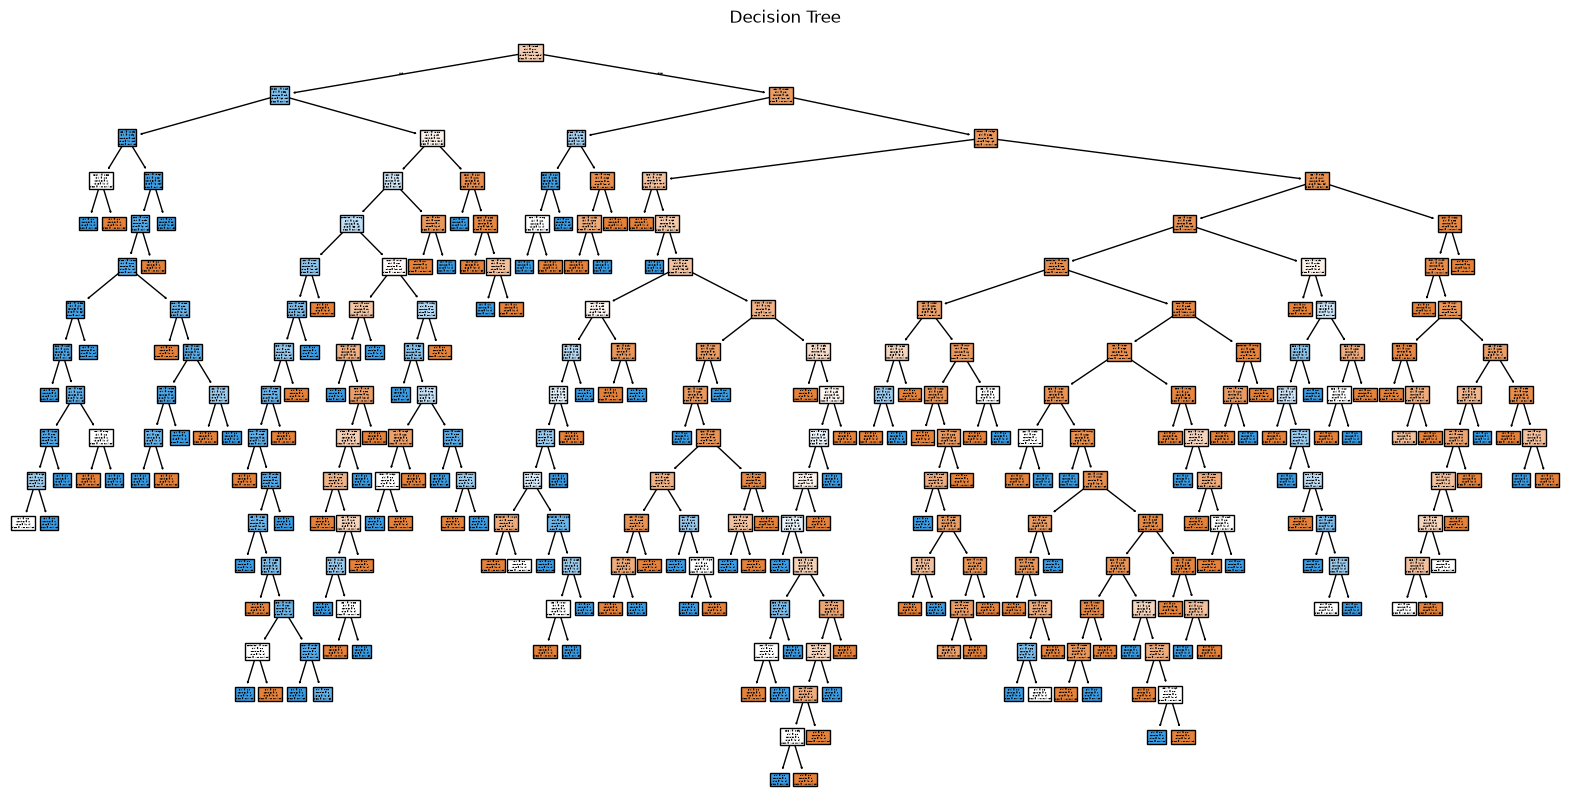

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(20,10))

plot_tree(dt, feature_names=features.columns, 
          class_names=['Not Survived','Survived'], filled=True)
plt.title("Decision Tree")
plt.show()
# 가지가 너무 깊어 읽기 어려움 = 과적합. 가지치기(pruning) 필요

## 과적합과 손잡이 조절

**과적합** = 연습 문제는 잘 맞추는데 시험은 못 맞추는 상태입니다.  
나무 깊이 등 **손잡이(하이퍼파라미터)** 를 줄이거나 교차검증으로 고릅니다.


In [ ]:
# 하이퍼파라미터 = 미리 정하는 설정. 과적합을 줄이고 검증 점수를 올리려 조정
# 최대 깊이 4, 잎 노드 최소 샘플 10으로 제한
hyper_dt=DecisionTreeClassifier(max_depth=3, min_samples_leaf=10)

In [ ]:
# 학습 데이터로 모델 훈련
hyper_dt.fit(X_train, y_train);

In [ ]:
# 학습 문제에 대한 예측값
hyper_dt_train=hyper_dt.predict(X_train)

In [ ]:
# 학습 데이터 정확도 계산
acc_train=accuracy_score(y_train, hyper_dt_train)

In [ ]:
# 학습 데이터 f1 계산
f1_train=f1_score(y_train, hyper_dt_train)

In [ ]:
# 가지를 줄인 모델의 학습 점수 확인
print(acc_train)
print(f1_train)

0.8384831460674157
0.7775628626692457


In [ ]:
# predict = 예측. 테스트 점수로 새 데이터 성능 확인
hyper_dt_test=hyper_dt.predict(X_test)
acc_test=accuracy_score(y_test, hyper_dt_test)
f1_test=f1_score(y_test, hyper_dt_test)
print(acc_test)
print(f1_test)

0.8044692737430168
0.7368421052631579


In [ ]:
# max_depth = 나무 최대 깊이. 깊을수록 학습은 잘하고 테스트는 흔들릴 수 있음
for depth in [2,3,4,5,6,7,8,9,10]:
    m=DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5, random_state=1)
    m.fit(X_train, y_train)
    ac_train=accuracy_score(y_train,m.predict(X_train))
    ac_test=accuracy_score(y_test, m.predict(X_test))
    print(f"depth={depth:2d} train={ac_train:.2f} test={ac_test:.2f} 차이:{ac_train-ac_test : .2f}")

depth= 2 train=0.81 test=0.72 차이: 0.09
depth= 3 train=0.84 test=0.80 차이: 0.03
depth= 4 train=0.85 test=0.80 차이: 0.04
depth= 5 train=0.85 test=0.79 차이: 0.06
depth= 6 train=0.87 test=0.78 차이: 0.09
depth= 7 train=0.88 test=0.80 차이: 0.08
depth= 8 train=0.88 test=0.79 차이: 0.09
depth= 9 train=0.88 test=0.80 차이: 0.08
depth=10 train=0.88 test=0.78 차이: 0.10


In [ ]:
# 여러 나무를 묶는 모델(랜덤포레스트·그래디언트부스팅) 불러오기
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
import time


In [ ]:
# 학습·예측·점수·시간을 한 번에 재는 함수
def eval_model(model, X_train, y_train, X_test, y_test):
  start_time=time.time()
  model.fit(X_train, y_train)
  elapse_time=time.time()-start_time

  y_train_pred=model.predict(X_train)
  y_test_pred=model.predict(X_test)

  acc_train=accuracy_score(y_train, y_train_pred)
  f1_train=f1_score(y_train, y_train_pred)
  acc_test=accuracy_score(y_test, y_test_pred)
  f1_test=f1_score(y_test, y_test_pred)

  return acc_train, f1_train, acc_test, f1_test, elapse_time

In [ ]:
# Bagging = 여러 모델을 모아 투표하듯 쓰는 방법
bagging_rf = RandomForestClassifier(n_estimators=10, random_state=1)
acc_train, f1_train, acc_test, f1_test, elapse_time = eval_model(bagging_rf, X_train, y_train, X_test, y_test)

print(f"Bagging 정확도: {acc_test:.2f}, F1-score: {f1_test:.2f}, 학습시간: {elapse_time:.2f}초")
# bagging_rf.fit(X_train, y_train)
# bagging_pred=bagging_rf.predict(X_test)

# print(accuracy_score(y_test, bagging_pred))
# print(f1_score(y_test, bagging_pred))

Bagging 정확도: 0.79, F1-score: 0.71, 학습시간: 0.06초
